In [1]:
!pip install -q pycocotools datasets huggingface_hub opencv-python-headless matplotlib pandas


In [4]:
import os
import json
from huggingface_hub import hf_hub_download, list_repo_files

os.makedirs("indian_traffic_coco/images", exist_ok=True)
ANNOTATION_FILE = "indian_traffic_coco/annotations.coco.json"
IMAGE_DIR = "indian_traffic_coco/images"

REPO_ID = "iisc-aim/UVH-26"

# 1. Inspect repository files to locate the native COCO JSON and images
repo_files = list_repo_files(repo_id=REPO_ID, repo_type="dataset")
json_files = [f for f in repo_files if f.endswith(".json")]

print("Found JSON files:", json_files)

# Download the validation or train COCO JSON file (val JSON is smaller and faster)
target_json = next((f for f in json_files if "val" in f.lower()), json_files[0])
downloaded_json_path = hf_hub_download(repo_id=REPO_ID, filename=target_json, repo_type="dataset")

with open(downloaded_json_path, "r") as f:
    full_coco = json.load(f)

print(f"\nLoaded full COCO JSON ({target_json}):")
print(f"Total Images: {len(full_coco['images'])} | Total Annotations: {len(full_coco['annotations'])} | Categories: {len(full_coco['categories'])}")

# 2. Match available files in the repository and download 50 sample images
# Create a map of base file names to their full repository paths
repo_img_map = {}
for filepath in repo_files:
    if filepath.lower().endswith((".jpg", ".jpeg", ".png")):
        base_name = os.path.basename(filepath)
        repo_img_map[base_name] = filepath

extracted_files = {}
subset_images = []
subset_img_ids = set()

# Select up to 50 images from the COCO metadata that actually exist in the repo files
count = 0
for img_info in full_coco["images"]:
    if count >= 50:
        break

    original_file_name = img_info["file_name"]
    base_name = os.path.basename(original_file_name)

    # If the exact base name matches a file in the repository
    if base_name in repo_img_map:
        repo_path = repo_img_map[base_name]
        out_path = os.path.join(IMAGE_DIR, base_name)

        # Download the individual image file
        print(f"Downloading [{count+1}/50]: {base_name}")
        downloaded_img = hf_hub_download(repo_id=REPO_ID, filename=repo_path, repo_type="dataset")

        # Copy or symlink to target directory
        import shutil
        shutil.copy(downloaded_img, out_path)

        extracted_files[base_name] = out_path

        img_copy = dict(img_info)
        img_copy["file_name"] = base_name
        subset_images.append(img_copy)
        subset_img_ids.add(img_info["id"])
        count += 1

subset_annotations = [ann for ann in full_coco["annotations"] if ann["image_id"] in subset_img_ids]

subset_coco = {
    "info": full_coco.get("info", {"description": "UVH-26 Indian Traffic Dataset"}),
    "licenses": full_coco.get("licenses", []),
    "categories": full_coco["categories"],
    "images": subset_images,
    "annotations": subset_annotations
}

with open(ANNOTATION_FILE, "w") as f:
    json.dump(subset_coco, f, indent=2)

print(f"\nReady! Created subset with {len(subset_images)} images and {len(subset_annotations)} bounding boxes at {ANNOTATION_FILE}")

Found JSON files: ['UVH-26-Train/UVH-26-MV-Train.json', 'UVH-26-Train/UVH-26-ST-Train.json', 'UVH-26-Val/UVH-26-MV-Val.json', 'UVH-26-Val/UVH-26-ST-Val.json', 'dataset_infos.json']

Loaded full COCO JSON (UVH-26-Val/UVH-26-MV-Val.json):
Total Images: 5297 | Total Annotations: 63497 | Categories: 14


UVH-26-Val/data/000/141253.png: reconstructing file:   0%|          |  0.00B / 2.82MB            

UVH-26-Val/data/000/141253.png: downloading bytes:           |  0.00B            

UVH-26-Val/data/000/178676.png: reconstructing file:   0%|          |  0.00B / 4.10MB            

UVH-26-Val/data/000/178676.png: downloading bytes:           |  0.00B            

UVH-26-Val/data/000/713343.png: reconstructing file:   0%|          |  0.00B / 4.27MB            

... (92 outputs left out)

UVH-26-Val/data/000/462630.png: downloading bytes:           |  0.00B            

UVH-26-Val/data/000/833417.png: reconstructing file:   0%|          |  0.00B / 3.88MB            

UVH-26-Val/data/000/833417.png: downloading bytes:           |  0.00B            


Ready! Created subset with 50 images and 289 bounding boxes at indian_traffic_coco/annotations.coco.json


In [5]:
from pycocotools.coco import COCO
import pandas as pd

# Load COCO dataset
coco = COCO(ANNOTATION_FILE)

# 1. Display Categories
cats = coco.loadCats(coco.getCatIds())
cat_df = pd.DataFrame(cats)
print("\n=== 1. INDIAN TRAFFIC CATEGORIES ===")
print(cat_df.to_string(index=False))

# 2. Category-wise Bounding Box & Image Counts
stats = []
for cat in cats:
    ann_ids = coco.getAnnIds(catIds=[cat['id']])
    img_ids = coco.getImgIds(catIds=[cat['id']])
    stats.append({
        "ID": cat['id'],
        "Category": cat['name'],
        "Bounding Boxes": len(ann_ids),
        "Images Present": len(img_ids)
    })

stats_df = pd.DataFrame(stats).sort_values(by="Bounding Boxes", ascending=False)
print("\n=== 2. BOUNDING-BOX DISTRIBUTION ===")
print(stats_df.to_string(index=False))

# 3. Inspect Sample Image & Annotation Dictionary Structure
sample_img_id = coco.getImgIds()[0]
print("\n=== 3. SAMPLE IMAGE METADATA ===")
print(coco.loadImgs([sample_img_id])[0])

sample_anns = coco.loadAnns(coco.getAnnIds(imgIds=[sample_img_id]))
print(f"\n=== 4. SAMPLE ANNOTATIONS (First 2 boxes in Image {sample_img_id}) ===")
print(sample_anns[:2])


loading annotations into memory...
Done (t=0.00s)
creating index...
index created!

=== 1. INDIAN TRAFFIC CATEGORIES ===
 id            name supercategory
  1       Hatchback       vehicle
  2           Sedan       vehicle
  3             SUV       vehicle
  4             MUV       vehicle
  5             Bus       vehicle
  6           Truck       vehicle
  7   Three-wheeler       vehicle
  8     Two-wheeler       vehicle
  9             LCV       vehicle
 10        Mini-bus       vehicle
 11 Tempo-traveller       vehicle
 12         Bicycle       vehicle
 13             Van       vehicle
 14          Others       vehicle

=== 2. BOUNDING-BOX DISTRIBUTION ===
 ID        Category  Bounding Boxes  Images Present
  8     Two-wheeler             127              40
  7   Three-wheeler              57              25
  1       Hatchback              28              21
  2           Sedan              15              14
  9             LCV              12              11
  5             Bus

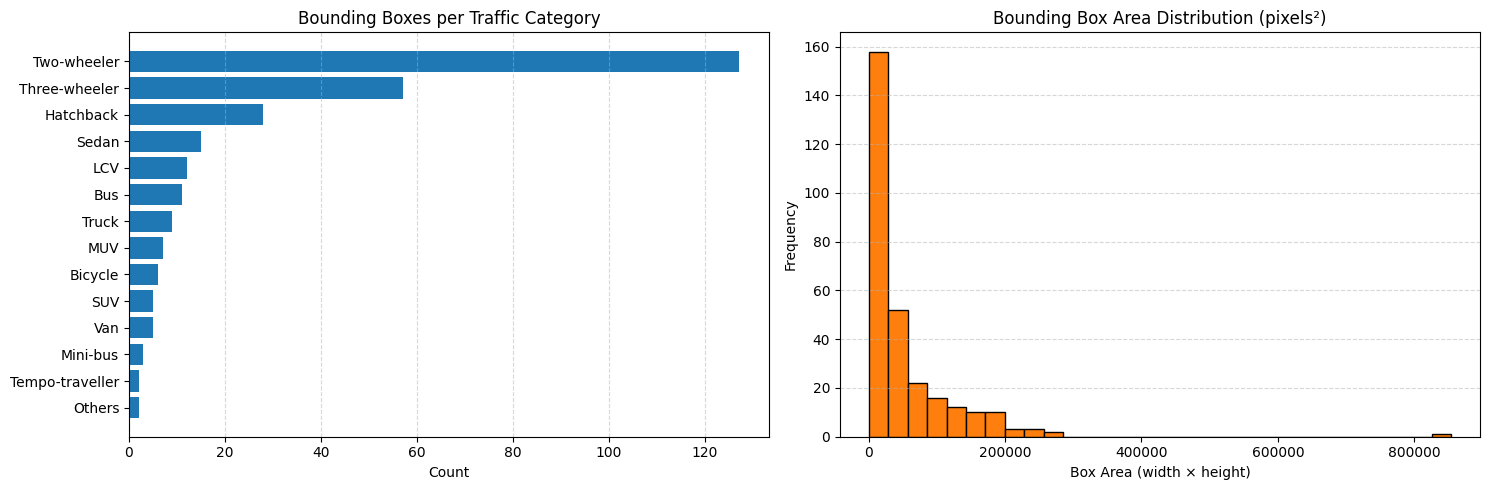

In [6]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: Bounding Box Count per Category
active_stats = stats_df[stats_df["Bounding Boxes"] > 0]
axes[0].barh(active_stats["Category"], active_stats["Bounding Boxes"], color="#1f77b4")
axes[0].invert_yaxis()
axes[0].set_title("Bounding Boxes per Traffic Category")
axes[0].set_xlabel("Count")
axes[0].grid(axis="x", linestyle="--", alpha=0.5)

# Plot 2: Bounding Box Area Distribution
all_anns = coco.loadAnns(coco.getAnnIds())
areas = [ann["area"] for ann in all_anns]
axes[1].hist(areas, bins=30, color="#ff7f0e", edgecolor="black")
axes[1].set_title("Bounding Box Area Distribution (pixels²)")
axes[1].set_xlabel("Box Area (width × height)")
axes[1].set_ylabel("Frequency")
axes[1].grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


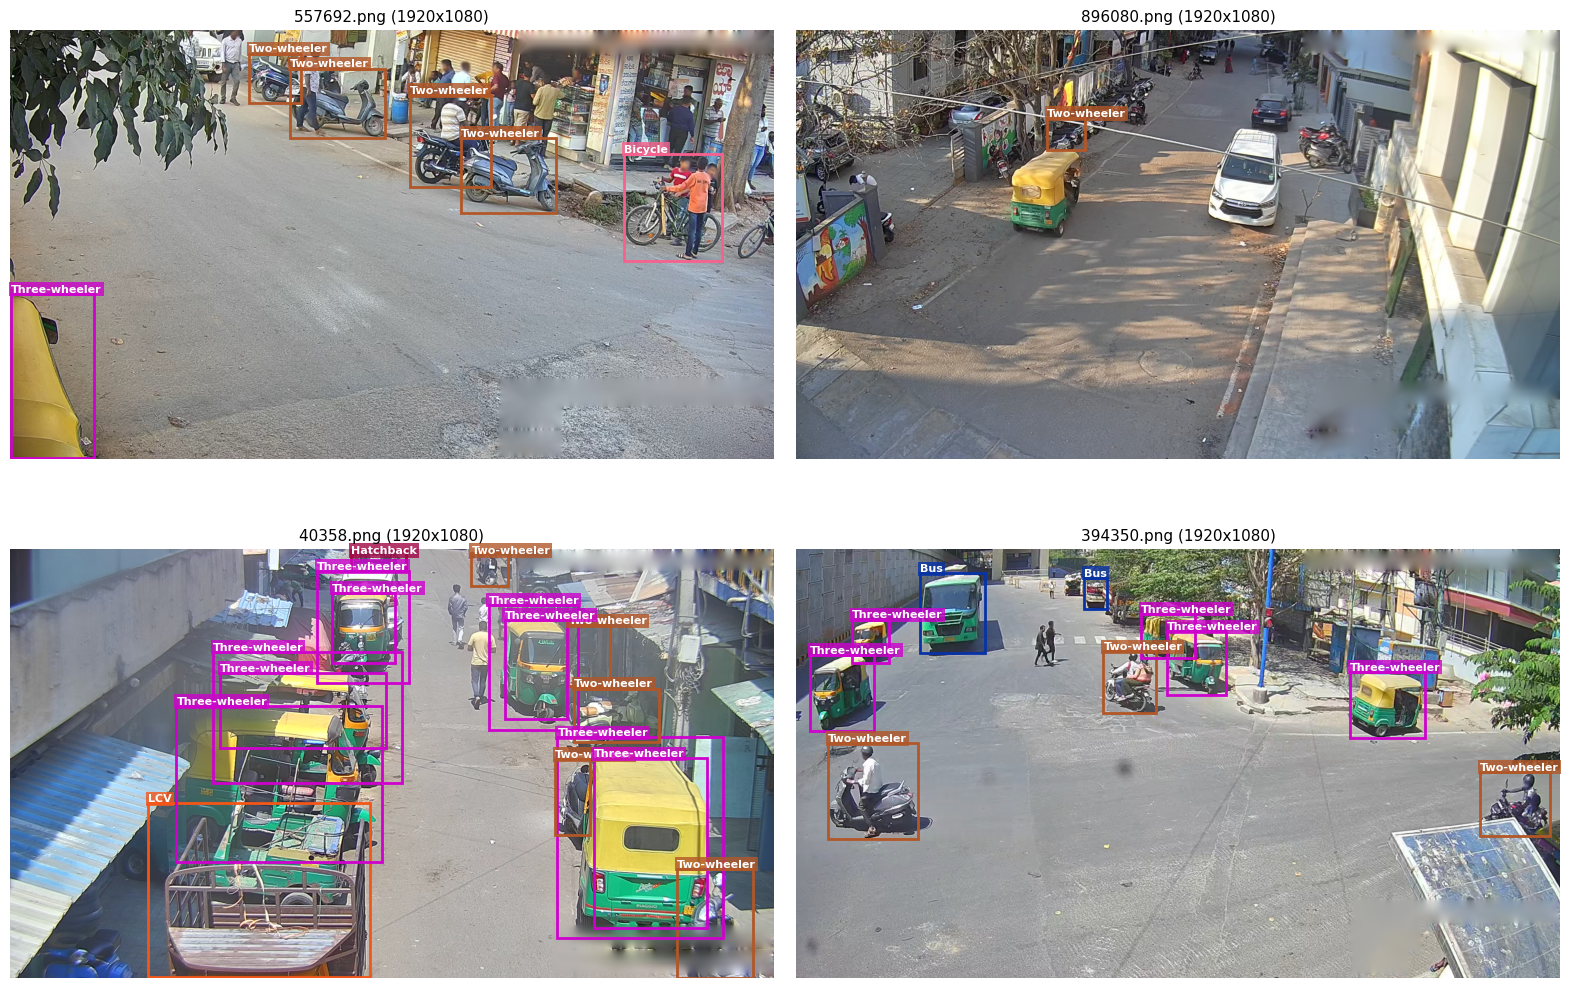

In [7]:
import cv2
import random
import matplotlib.patches as patches

img_ids = coco.getImgIds()
sample_ids = random.sample(img_ids, min(4, len(img_ids)))
cat_map = {cat["id"]: cat["name"] for cat in cats}

# Generate distinct colors per category
random.seed(42)
colors = {cat["id"]: (random.random(), random.random(), random.random()) for cat in cats}

fig, axes = plt.subplots(2, 2, figsize=(16, 11))
axes = axes.flatten()

for ax, img_id in zip(axes, sample_ids):
    img_info = coco.loadImgs([img_id])[0]
    img_path = os.path.join(IMAGE_DIR, img_info["file_name"])

    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    ax.imshow(img)
    ax.set_title(f"{img_info['file_name']} ({img_info['width']}x{img_info['height']})", fontsize=11)
    ax.axis("off")

    anns = coco.loadAnns(coco.getAnnIds(imgIds=[img_id]))
    for ann in anns:
        x, y, w, h = ann["bbox"]
        cat_id = ann["category_id"]
        label = cat_map[cat_id]
        color = colors[cat_id]

        rect = patches.Rectangle((x, y), w, h, linewidth=2, edgecolor=color, facecolor="none")
        ax.add_patch(rect)
        ax.text(
            x, max(y - 4, 12), label,
            color="white", fontsize=8, fontweight="bold",
            bbox=dict(facecolor=color, alpha=0.8, edgecolor="none", pad=1.5)
        )

plt.tight_layout()
plt.show()
